# E225 · Does the controller benefit from representation health?

**Complete** · E225 finished  
Updated 2026-11-23T00:23:59+01:00 Stockholm

The primary comparison uses eight capture-disjoint BDD walks, two paired mask draws per walk, and 64-pixel MAE inputs. Each 768-arrival block has 384 skips, 363 quarter-rate updates and 21 full-rate updates. The five-task balanced-accuracy mean is integrated over arrival time. Both mask draws are averaged within each walk before the comparison. Probe labels are used only for evaluation.

The real and image-only policies reuse E224’s frozen +16 Ridge weights. The placebo policy is fitted separately on the same archived action targets, with the real policy’s Ridge strength. Its health comes from contiguous four-observation blocks from development walks, matched on elapsed time, cumulative actions and recent actions. The three adaptive deployments use only observed inputs. The shuffle preserves real-health action counts within each 96-arrival clip.

| Development feature | Real mean | Placebo mean | Real SD | Placebo SD |
| --- | --- | --- | --- | --- |
| Current reconstruction MSE | 0.87158 | 0.87349 | 0.11532 | 0.1148 |
| FIFO reconstruction MSE | 0.86482 | 0.86508 | 0.021511 | 0.020901 |
| RankMe | 8.403 | 8.409 | 1.1627 | 1.1732 |
| Variance | 0.11255 | 0.11295 | 0.049257 | 0.050433 |

### Real health relative to each control

Paired effects in percentage points with 95% walk-bootstrap intervals.

| Control | Five-task mean | Walk wins | scene | weather | lighting | traffic light | pedestrian | scene kNN |
| --- | --- | --- | --- | --- | --- | --- | --- | --- |
| Clock + image + placebo health | +0.189 [+0.053, +0.340] | 6/8 | +0.213 [-0.048, +0.498] | +0.149 [-0.271, +0.517] | -0.054 [-0.126, -0.005] | +0.197 [-0.023, +0.479] | +0.438 [+0.137, +0.728] | +0.337 [+0.098, +0.579] |
| Clock + image | +0.071 [-0.082, +0.244] | 4/8 | -0.078 [-0.445, +0.314] | +0.007 [-0.430, +0.433] | -0.036 [-0.106, +0.034] | +0.378 [+0.122, +0.637] | +0.085 [-0.114, +0.309] | +0.147 [-0.213, +0.501] |
| Real health clip shuffle | +0.071 [-0.090, +0.232] | 5/8 | -0.030 [-0.339, +0.242] | -0.084 [-0.347, +0.160] | -0.008 [-0.058, +0.043] | +0.108 [-0.045, +0.244] | +0.371 [-0.002, +0.784] | +0.123 [-0.009, +0.250] |
| Fixed 50% | -0.059 [-0.190, +0.064] | 3/8 | -0.124 [-0.552, +0.281] | -0.223 [-0.895, +0.458] | -0.044 [-0.078, -0.014] | +0.195 [+0.060, +0.328] | -0.101 [-0.649, +0.396] | +0.268 [-0.046, +0.550] |

**Strong-positive threshold not met.** It requires +0.25 pp over placebo, at least seven positive walks and an interval above zero.

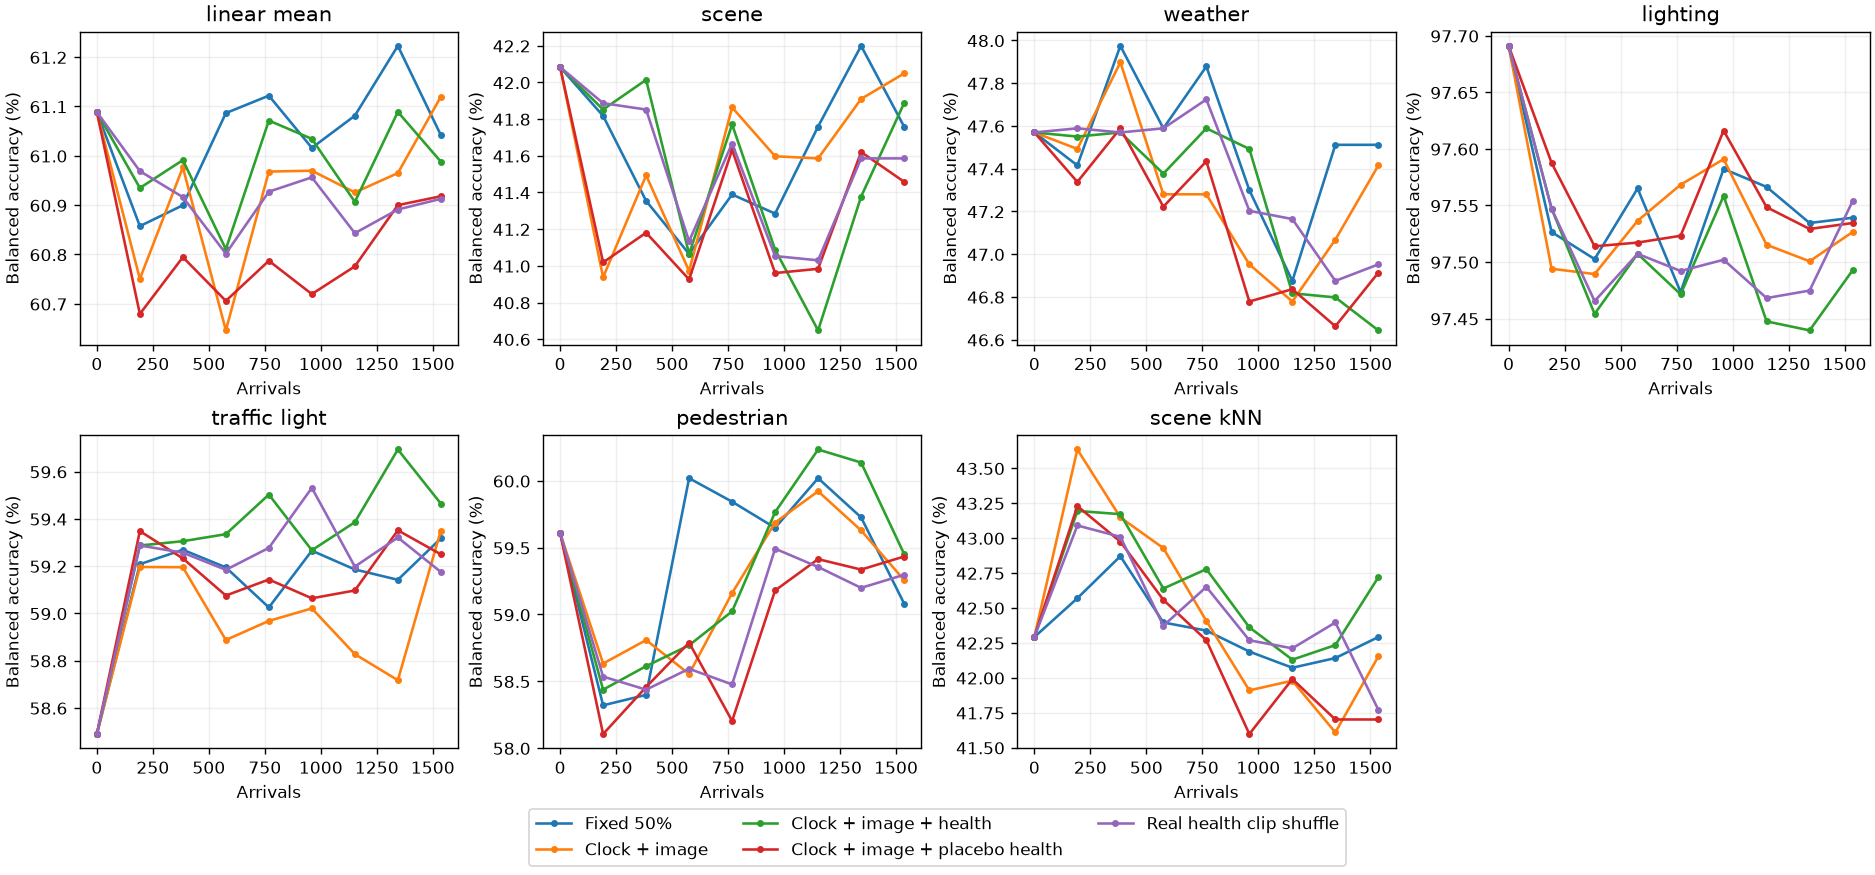

### +16 audit on common fixed-policy states

256 origins and 768 branches. Lower O3 and higher semantic scores are favorable. O3 ties use ±0.01 and semantic ties use ±0.1 pp. The longer audit runs at clip slots 1 and 9 if more than half of short-horizon semantic pairs are tied.

| Pairwise O3–semantic agreement | Comparable | O3 ties | Semantic ties |
| --- | --- | --- | --- |
| 53.3% | 225 | 6.8% | 68.6% |

| Action | Mean ΔO3 | Mean semantic Δ (pp) | Mean reconstruction Δ | Mean retrieval margin Δ |
| --- | --- | --- | --- | --- |
| Skip | -0.89928 | -0.00424 | -0.01022 | +0.00001 |
| 0.25× | -0.93483 | -0.00324 | -0.00967 | -0.00001 |
| 1× | -0.97527 | +0.00200 | -0.00849 | -0.00003 |

| Frozen predictor | Mean O3 regret | Skip, 0.25×, 1× selections |
| --- | --- | --- |
| Clock + actions | 0.06200 | 148, 108, 0 |
| Clock + image | 0.06048 | 134, 122, 0 |
| Clock + image + health | 0.05704 | 109, 147, 0 |
| Clock + image + placebo health | 0.06184 | 144, 112, 0 |

### +80 audit on common fixed-policy states

32 origins and 96 branches. Lower O3 and higher semantic scores are favorable. O3 ties use ±0.01 and semantic ties use ±0.1 pp. The longer audit runs at clip slots 1 and 9 if more than half of short-horizon semantic pairs are tied.

| Pairwise O3–semantic agreement | Comparable | O3 ties | Semantic ties |
| --- | --- | --- | --- |
| 40.0% | 15 | 44.8% | 72.9% |

| Action | Mean ΔO3 | Mean semantic Δ (pp) | Mean reconstruction Δ | Mean retrieval margin Δ |
| --- | --- | --- | --- | --- |
| Skip | -1.76186 | -0.06422 | +0.06530 | -0.00047 |
| 0.25× | -1.77013 | -0.07185 | +0.06616 | -0.00046 |
| 1× | -1.78201 | -0.08421 | +0.06722 | -0.00046 |

| Policy | Policy seconds per 1,536 arrivals | Evaluation seconds |
| --- | --- | --- |
| Fixed 50% | 8.3 | 25.7 |
| Clock + image | 10.5 | 2.7 |
| Clock + image + health | 10.6 | 2.7 |
| Clock + image + placebo health | 10.6 | 2.7 |
| Real health clip shuffle | 8.6 | 2.7 |